In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
}

In [5]:
results = pandas.read_parquet(TIMESERIES_TABLE_PATH)

In [6]:
results

,a,e,periapsis_phase,Macc,Porb,Mcomp,Rcomp,b,rv,rv_times,...,cadence,baseline,pristine idx,realistic_idx,fitted_a,fitted_b,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb
0,22.857143,0,0,9.166667,12518.204690,1.0,1.0,3.265306,"[6785.97707245586, 16159.450818758382, 25160.2...","[2460676.5, 2460976.5, 2461276.5, 2461576.5, 2...",...,300,1825,40404,59213,9.033854,0.075054,4.017479,0.708869,4.235024,4427.567981
1,0.421429,0,0,26.875000,18.926790,1.0,1.0,7.959184,"[1198464.1093692316, 1067863.4022070207, 62839...","[2460676.5, 2460976.5, 2461276.5, 2461576.5]",...,300,1095,7246,88184,10.088144,7.449340,49.997603,0.884567,0.000071,1638.854756
2,0.935714,0,0,10.208333,98.751295,1.0,1.0,3.673469,"[300295.81681649596, 331889.73976900394]","[2460676.5, 2460976.5]",...,300,365,16705,16325,9.051675,7.516666,40.557397,0.077727,4.885373,1543.006317
3,5.500000,0,0,5.000000,1923.387707,1.0,1.0,4.489796,"[49034.81941624917, 70715.99518017081, 75736.4...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1825,28050,13672,5.495891,2.949824,4.998295,0.001635,6.145031,1921.505987
4,5.500000,0,0,21.666667,989.574811,1.0,1.0,4.693878,"[281419.47511062626, 212513.65241254558, -3502...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1825,28091,74574,5.500070,5.513821,21.667466,0.000004,3.766057,989.576386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,100.000000,0,0,10.208333,109100.793131,1.0,1.0,5.714286,"[458.63229375230196, 599.8746146628163, 861.74...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1095,55705,19884,0.570362,0.581078,0.122655,0.428921,5.995125,148.491371
4996,0.292857,0,0,13.333333,15.290038,1.0,1.0,5.306122,"[-19623.49897052664, -739925.3279722307, -5278...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1825,4408,50540,0.661957,4.594280,16.447256,0.438692,5.874601,47.095499
4997,0.807143,0,0,10.208333,79.114032,1.0,1.0,4.897959,"[-356937.2840878498, 187463.48462410993, 84685...","[2460676.5, 2460706.5, 2460736.5, 2460766.5, 2...",...,30,1095,14355,21509,0.601270,4.630003,3.628783,0.768174,3.122822,79.153383
4998,0.100000,0,0,5.000000,4.715446,1.0,1.0,3.877551,"[379639.813847714, 12299.413477777503]","[2460676.5, 2460976.5]",...,300,365,475,60415,4.836469,8.521346,12.758806,0.642427,1.469031,1047.371292


In [7]:
# for a, b in params:
#     results[f'{a} err'] = numpy.log10(numpy.abs(results[b] - results[a]))

In [8]:
# results['close'] = (
#     numpy.isclose(results['a'], results['fitted_a'], rtol=1)
#     & numpy.isclose(results['Macc'], results['fitted_Macc'], rtol=1)
#     # & numpy.isclose(results['Porb'], results['fitted_porb'], rtol=0.1)
# )
# results['close'].value_counts()

In [9]:
# results[['a', 'b', 'fitted_a', 'Macc', 'fitted_Macc', 'Porb', 'fitted_porb', 'close']]

In [10]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Porb', hue='Porb err', col='cadence',
#     aspect=.5, jitter=True,
# )
# pyplot.yscale('log')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [11]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Macc', hue='Macc err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [12]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='a', hue='a err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))
# pyplot.yscale('log')

In [13]:
# # Scatter plot version
# def plot_relation(x, y='RV accuracy', logx=True, logy=True):
#     for cadence, cadence_group in results.groupby('cadence'):
#         baselines = cadence_group['baseline'].unique()
#         baselines = numpy.sort(baselines)
#         fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
#         if len(baselines) == 1:
#             axes = [axes]
#         for ax, baseline in zip(axes, baselines):
#             subset = cadence_group[cadence_group['baseline'] == baseline]
#             ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
#             ax.set_xlabel(x)
#             ax.set_ylabel(y)
#             if logx:
#                 ax.set_xscale('log')
#             if logy:
#                 ax.set_yscale('log')
#             colors = subset['close'].map({True: 'tab:blue', False: 'tab:red'})
#             ax.scatter(subset[x], subset[y], c=colors, alpha=0.7, s=4, label=None)
#             handles = [
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='close', markerfacecolor='tab:blue', markersize=8),
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='not close', markerfacecolor='tab:red', markersize=8)
#             ]
#             if ax == axes[0]:
#                 ax.legend(handles=handles, title='close')
#             else:
#                 ax.legend_.remove() if hasattr(ax, 'legend_') and ax.legend_ else None
#         pyplot.tight_layout()
#         pyplot.show()

In [14]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            close =  numpy.isclose(subset[x], subset[params[x]], rtol=0.1)
            # Bin the data
            xdata = subset[x]
            ydata = subset[y]
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # 2D histogram for "close" fraction
            hist_total, _, _ = numpy.histogram2d(xdata, ydata, bins=[xbins, ybins])
            hist_close, _, _ = numpy.histogram2d(xdata[close], ydata[close], bins=[xbins, ybins])
            # Avoid division by zero
            with numpy.errstate(invalid='ignore', divide='ignore'):
                frac_close = hist_close / hist_total
            # Plot
            mesh = ax.pcolormesh(xbins, ybins, frac_close.T, cmap='coolwarm_r', vmin=0, vmax=1)
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Fraction close')
        pyplot.tight_layout()
        pyplot.show()

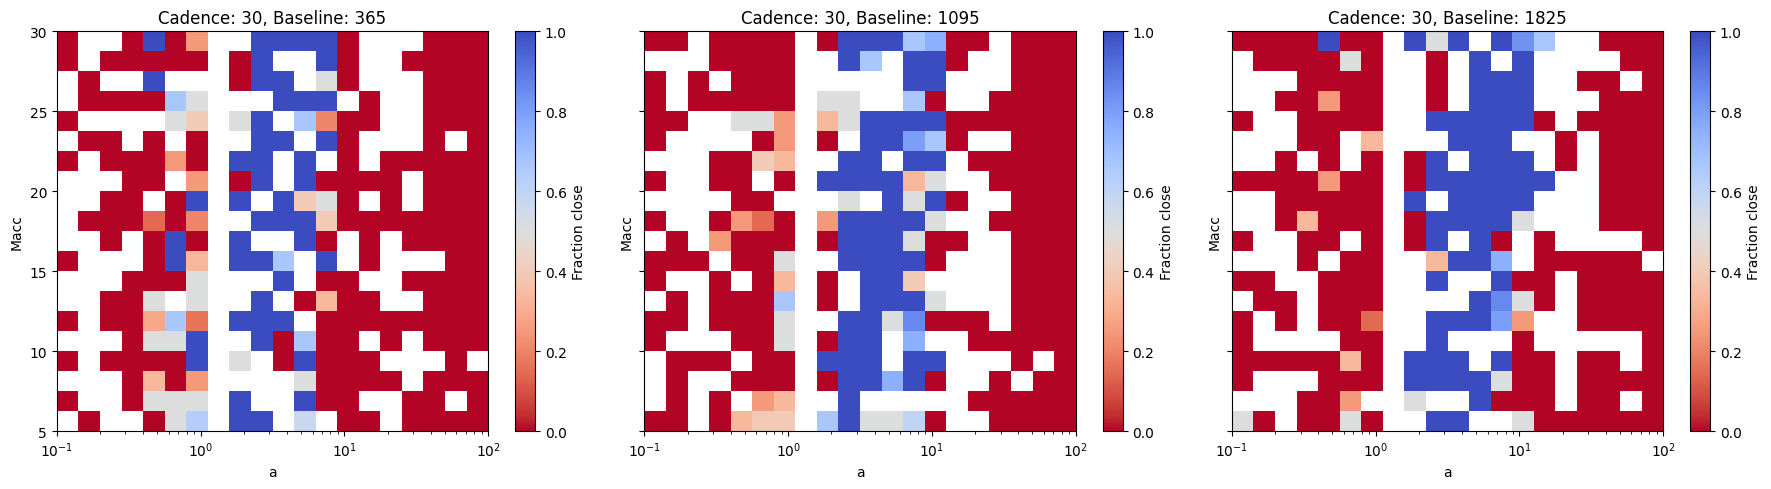

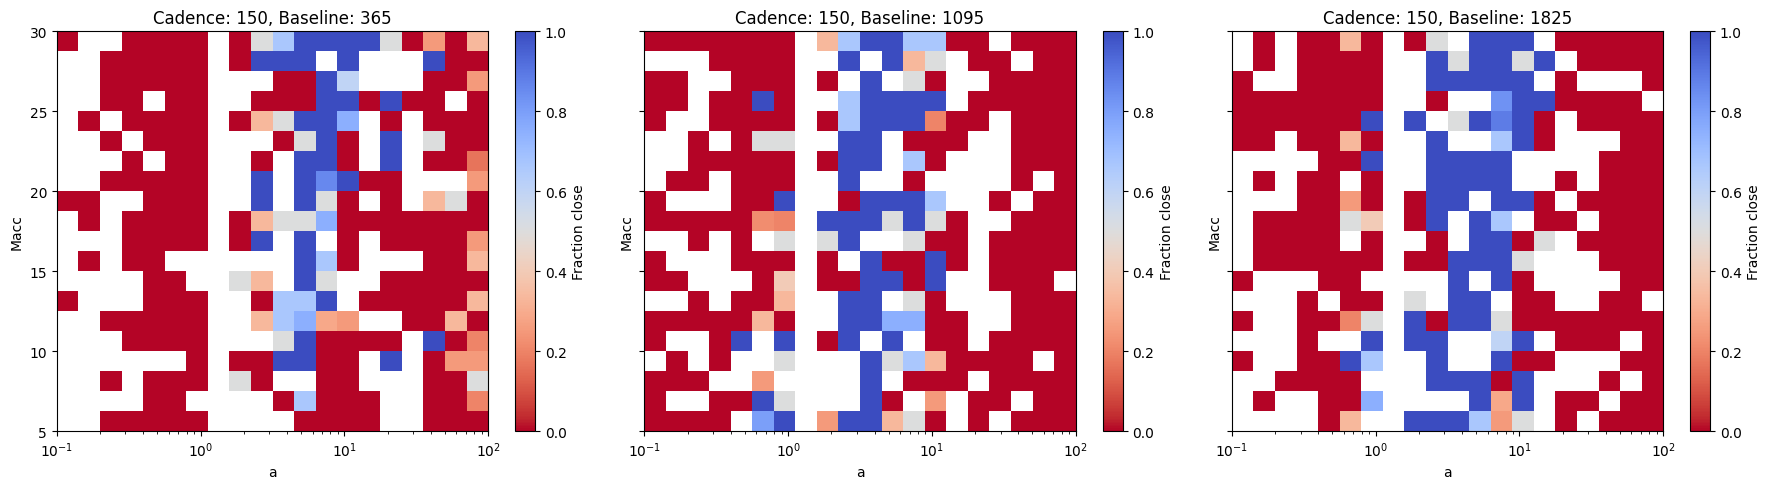

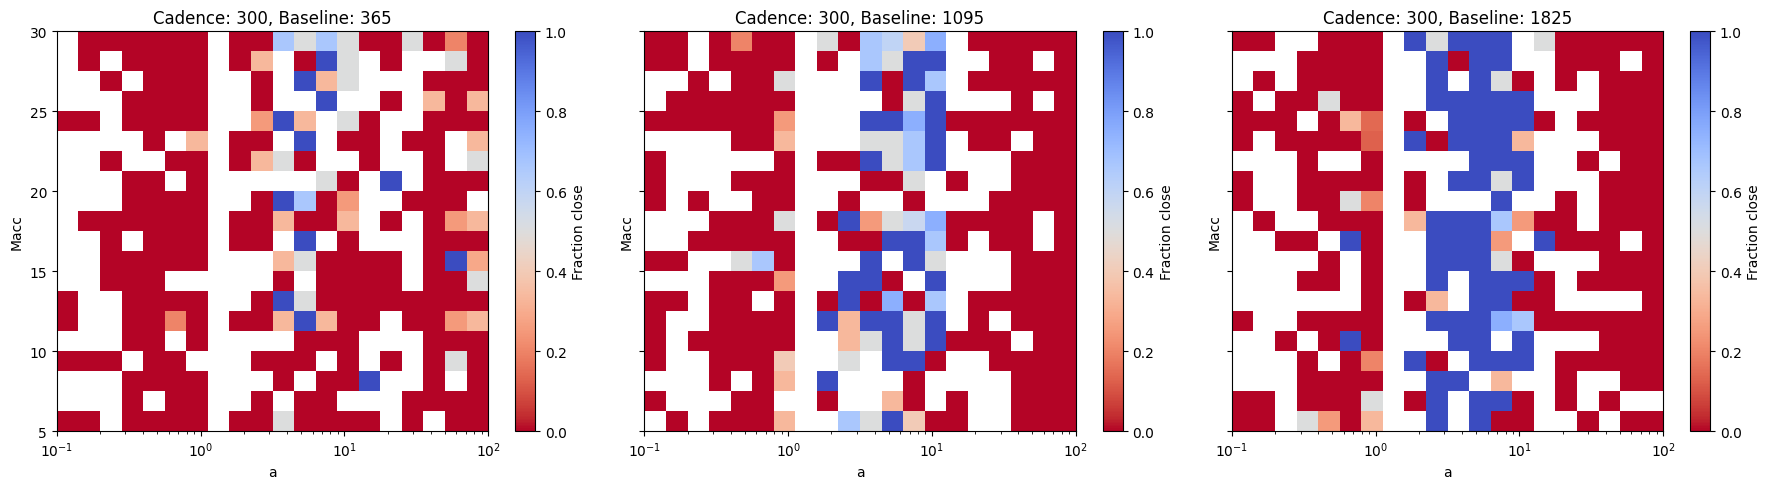

In [15]:
plot_relation('a', 'Macc', logy=False)

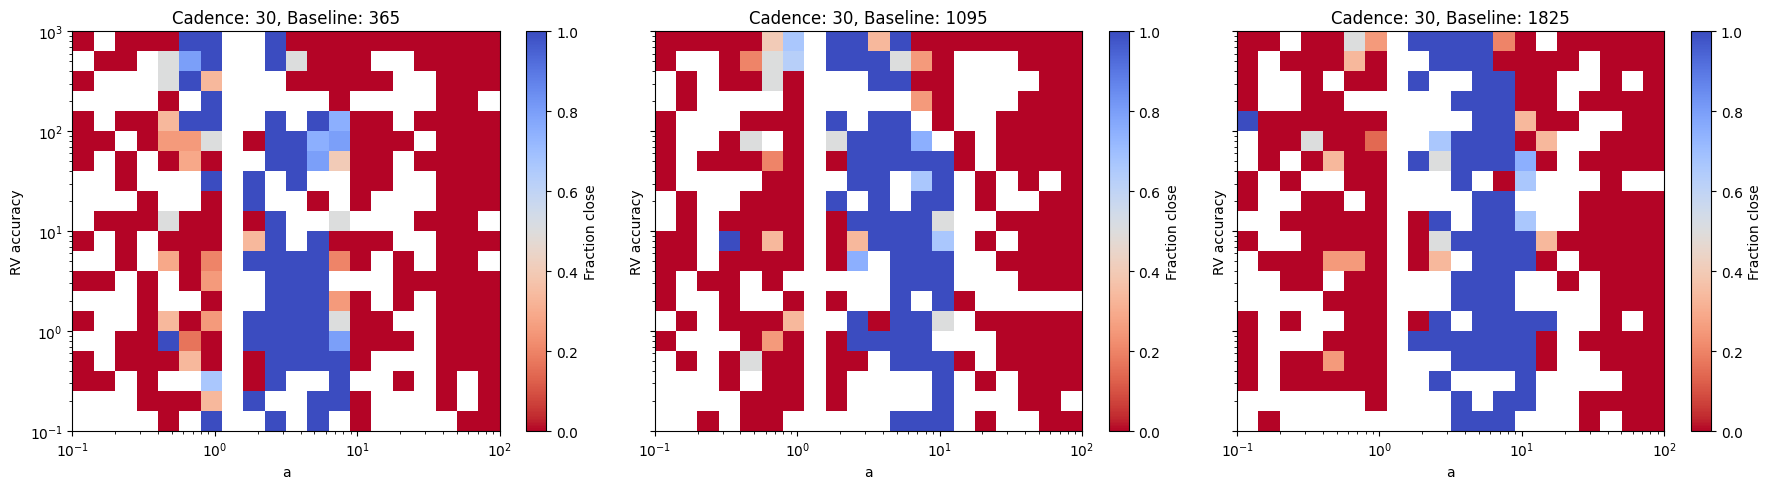

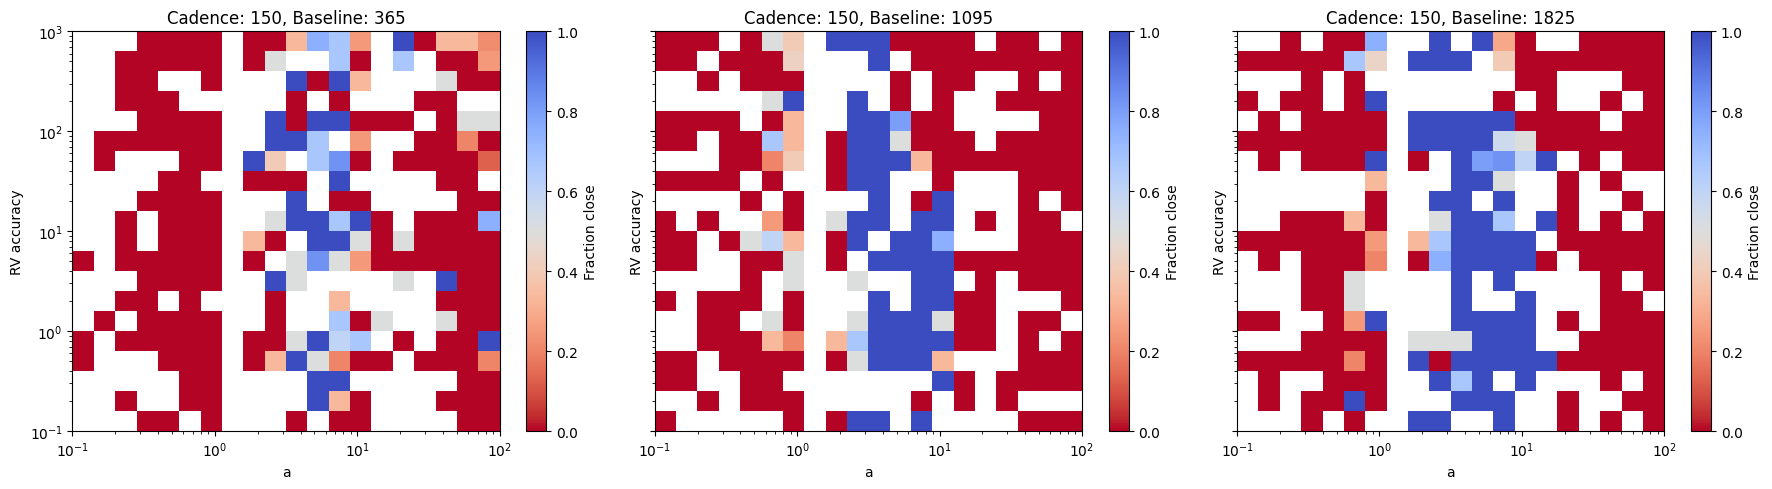

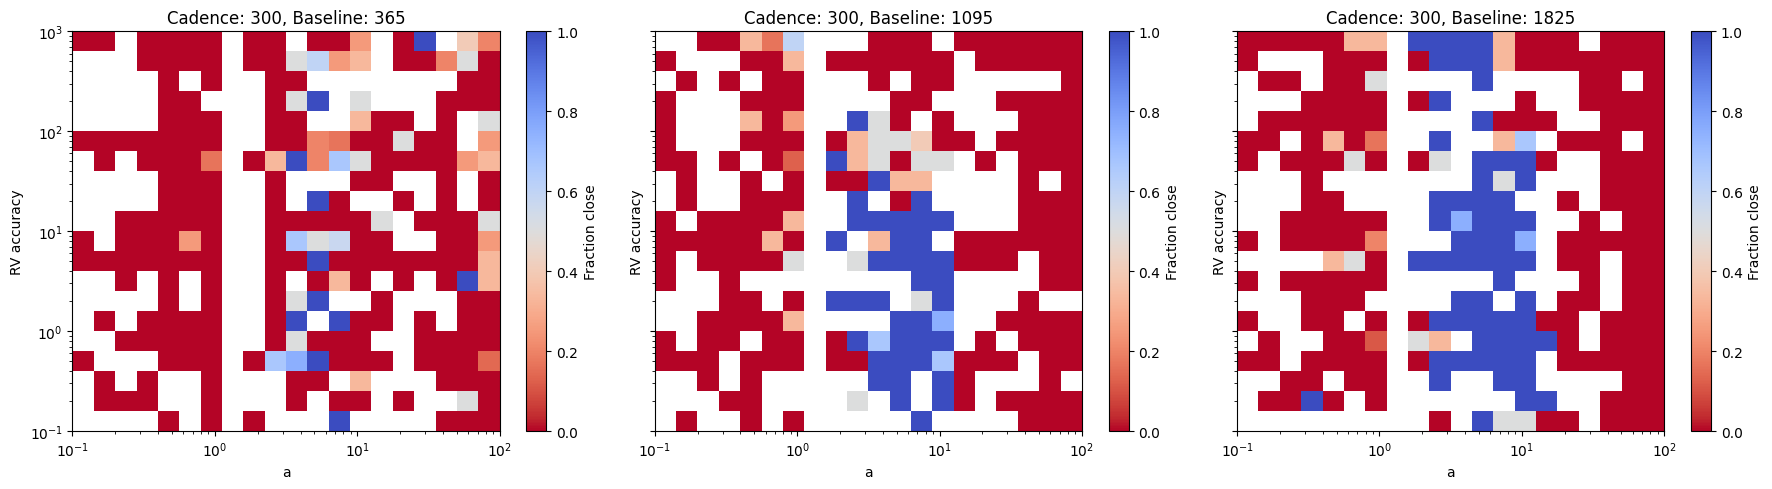

In [16]:
plot_relation('a')

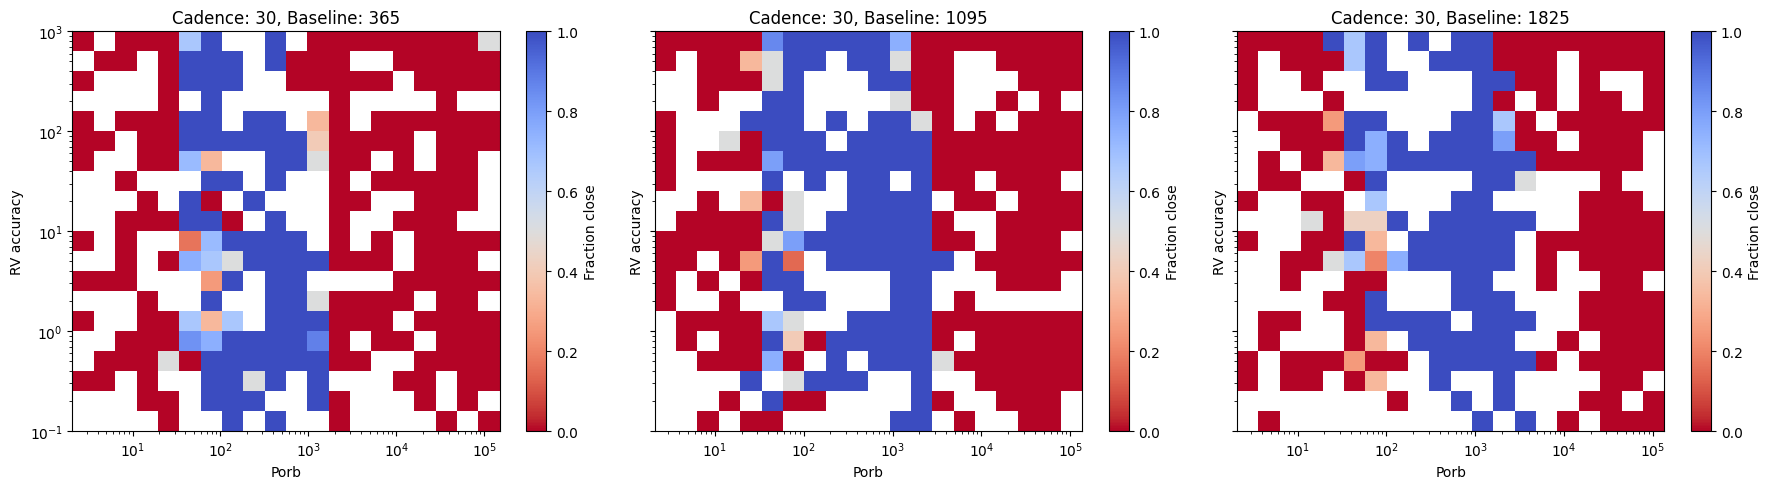

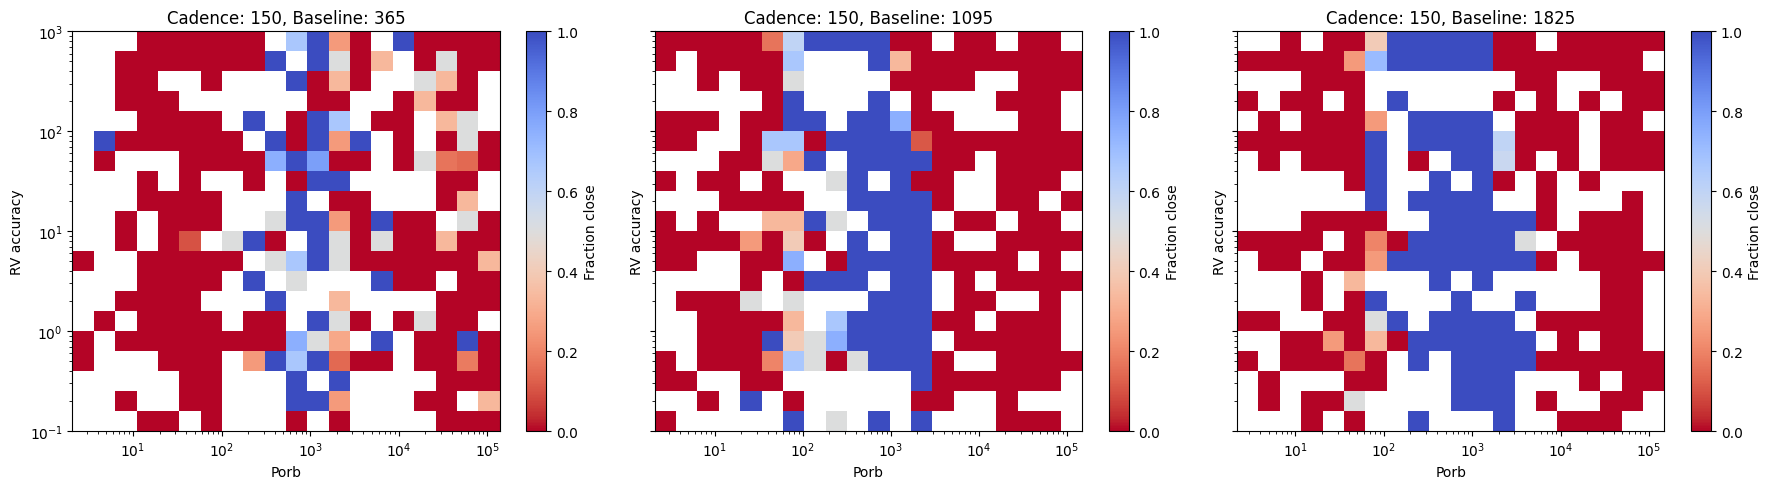

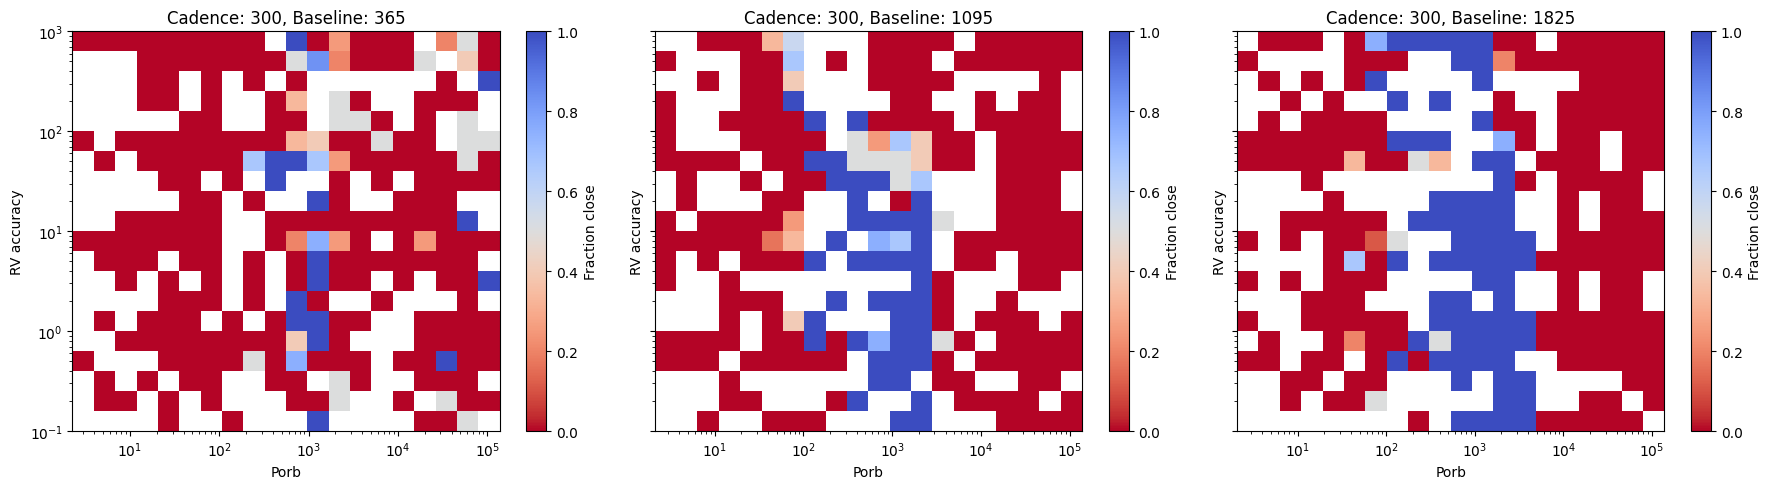

In [17]:
plot_relation('Porb')

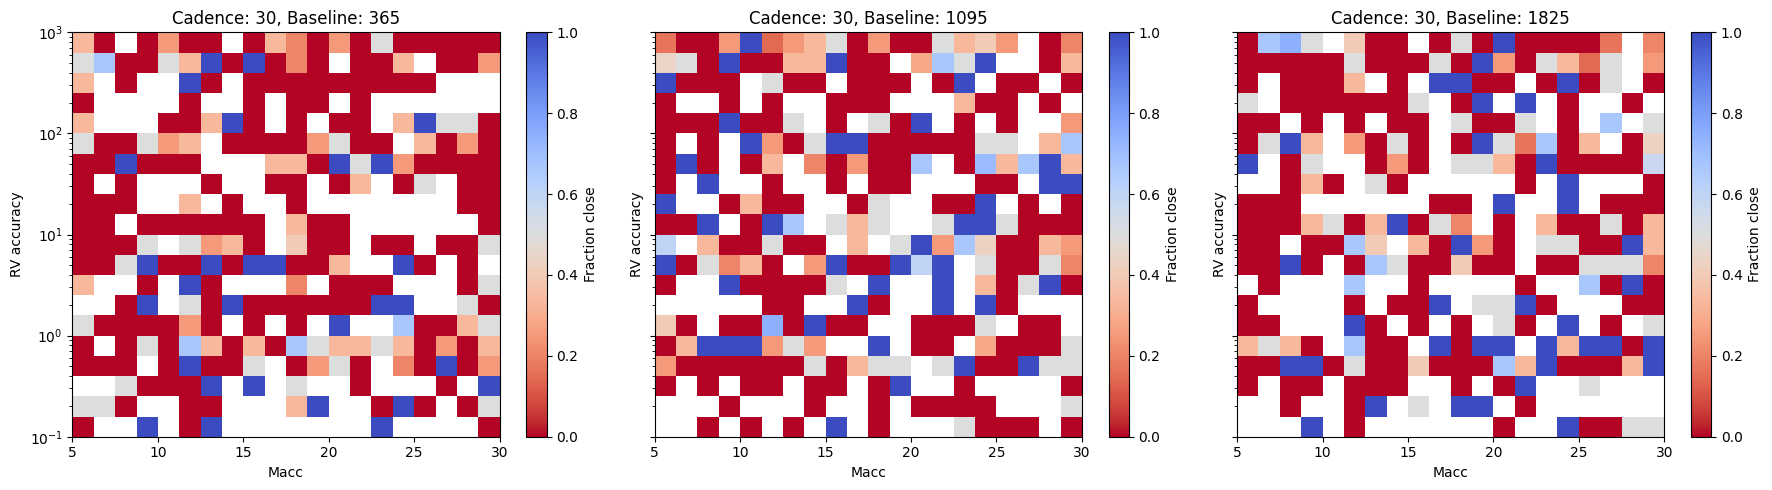

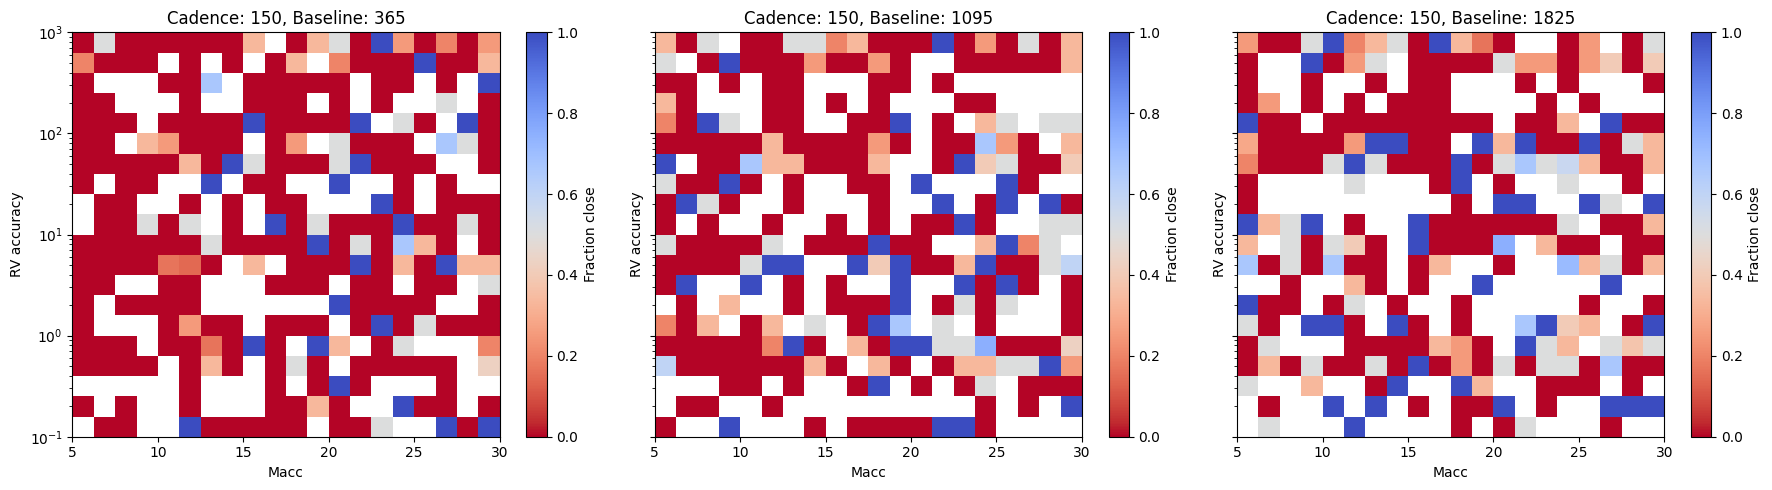

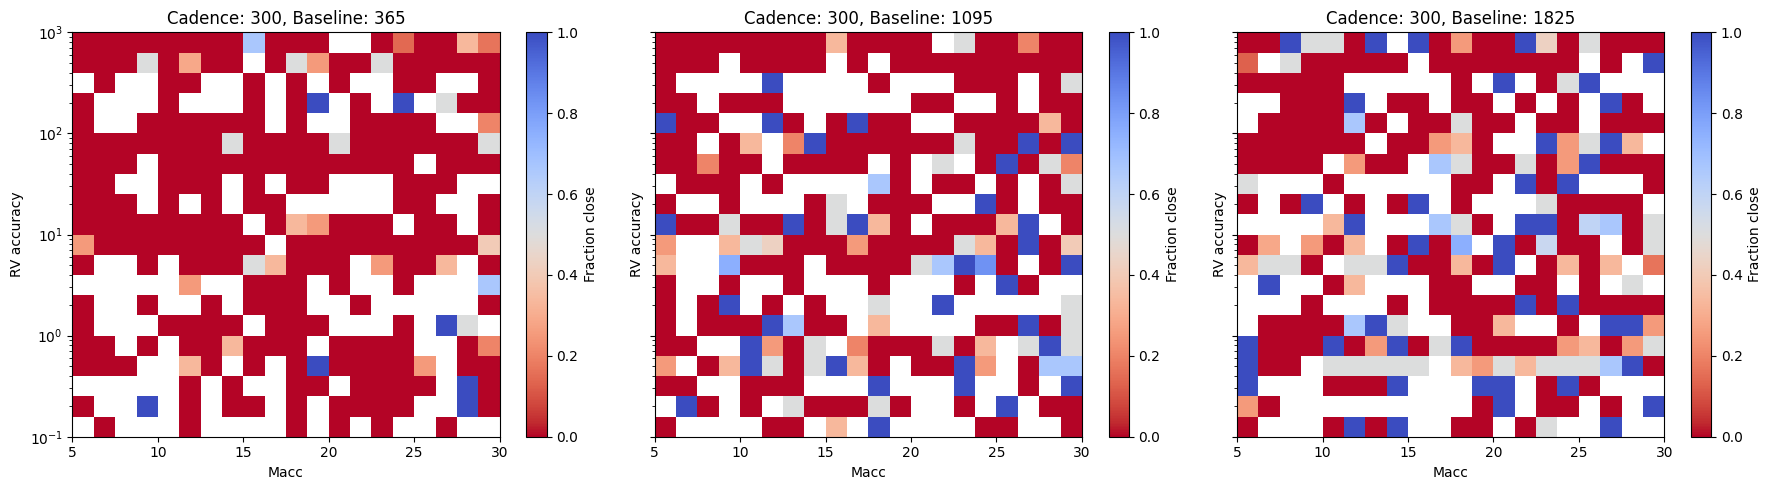

In [18]:
plot_relation('Macc', logx=False)

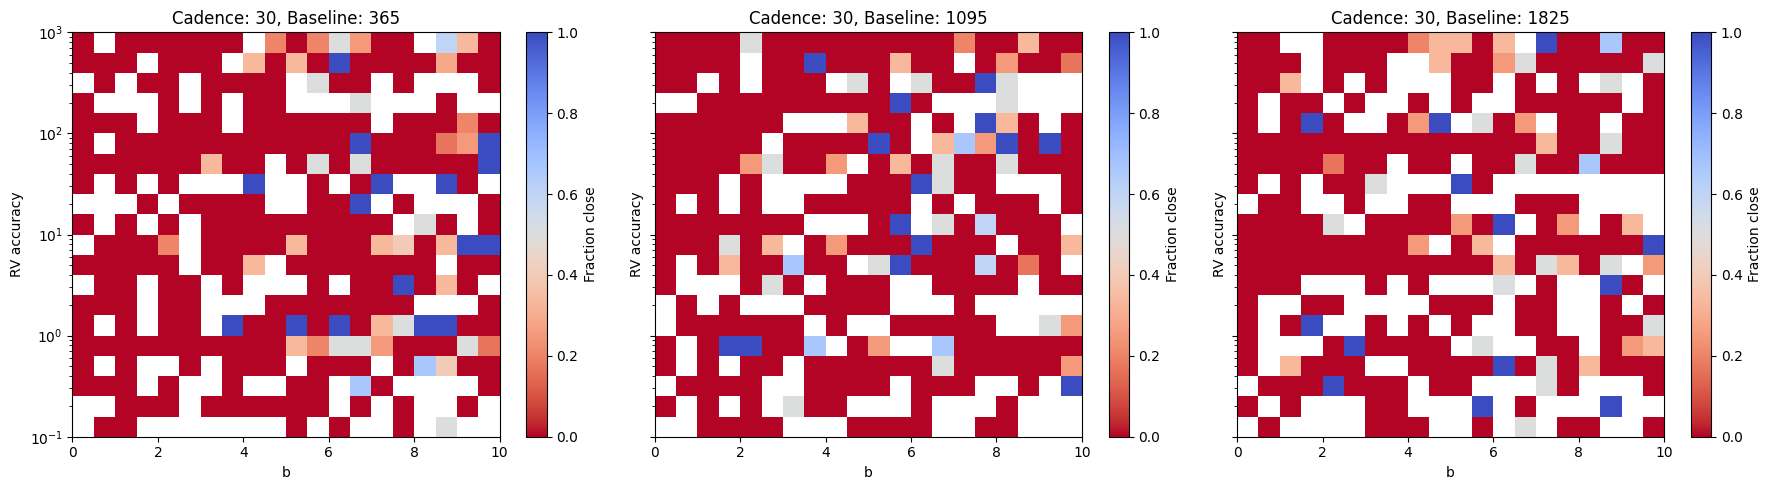

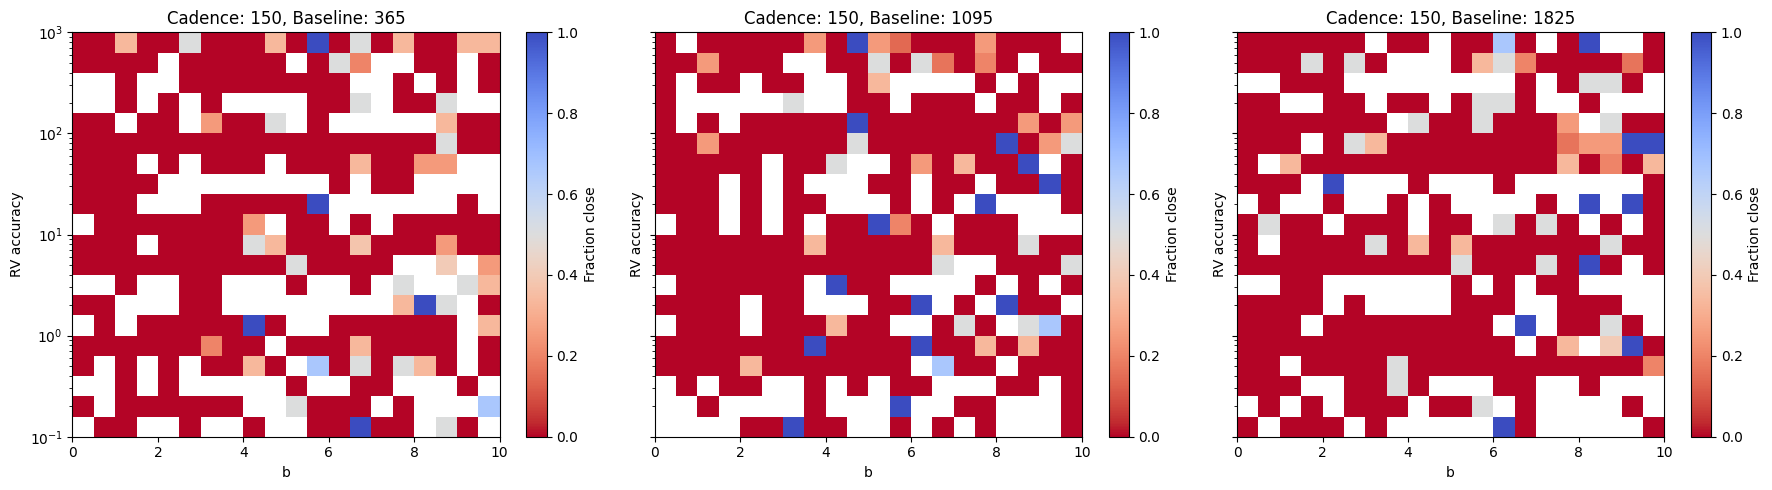

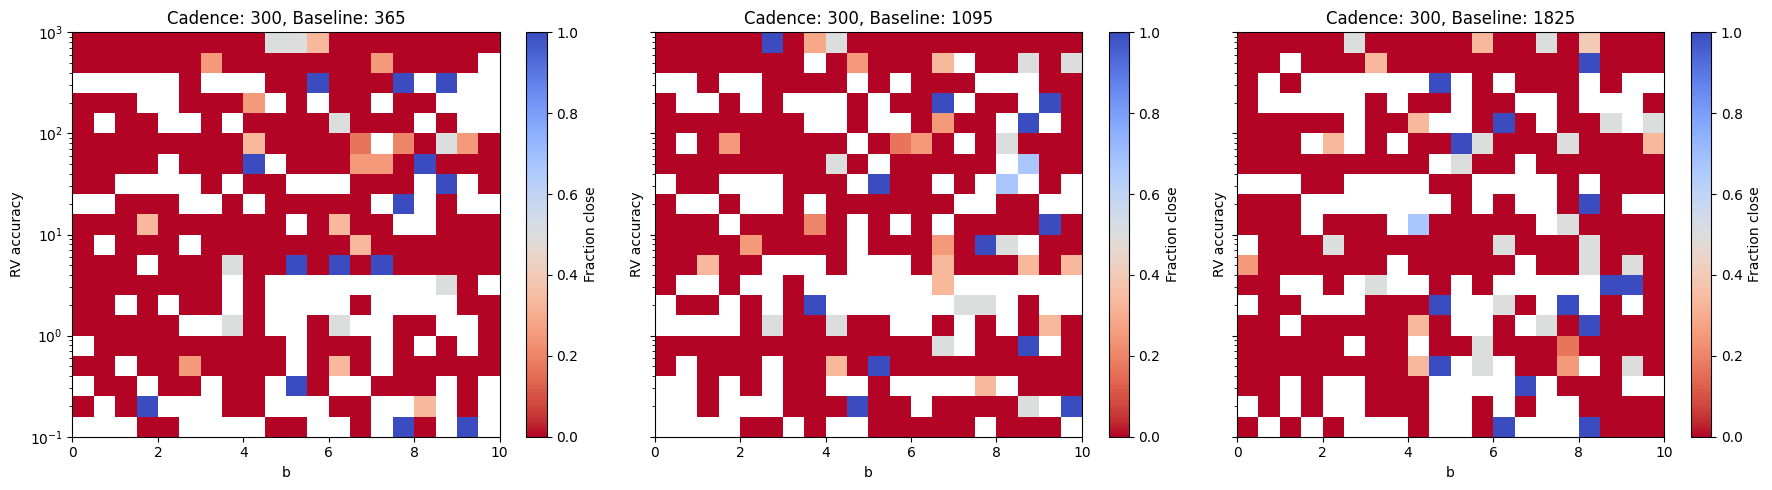

In [19]:
plot_relation('b', logx=False)